# Advanced Model Training: DNN with SMOTE and Feature Selection
This notebook applies advanced techniques to improve detection of rare attacks (R2L and U2R).

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  0


In [2]:
# 1. Load Data
print("Loading data arrays...")
X_train = np.load('data/X_train.npy')
y_train = np.load('data/y_train.npy')
X_test = np.load('data/X_test.npy')
y_test = np.load('data/y_test.npy')

Loading data arrays...


In [3]:
# 2. Feature Selection (Reduce Noise)
print("Training Random Forest to identify top features...")
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Keep top 40 most important features
importances = rf.feature_importances_
top_indices = np.argsort(importances)[::-1][:40]

X_train_fs = X_train[:, top_indices]
X_test_fs = X_test[:, top_indices]
print(f"Reduced feature count from {X_train.shape[1]} to {X_train_fs.shape[1]}")

Training Random Forest to identify top features...
Reduced feature count from 122 to 40


In [4]:
# 3. Handle Class Imbalance with SMOTE
print("Applying SMOTE to balance the classes...")
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_fs, y_train)
print(f"Original training shape: {X_train_fs.shape}, SMOTE shape: {X_train_sm.shape}")

Applying SMOTE to balance the classes...
Original training shape: (125973, 40), SMOTE shape: (336715, 40)


In [5]:
# 4. Build Deep Neural Network (DNN)
model = Sequential([
    tf.keras.Input(shape=(X_train_sm.shape[1],)),
    
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    
    Dense(5, activation='softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 189,445 (740.02 KB)

 Trainable params: 187,653 (733.02 KB)

 Non-trainable params: 1,792 (7.00 KB)

In [6]:
# 5. Train the DNN
# Note: Since SMOTE multiplies our data size significantly, we increase batch size.
history = model.fit(X_train_sm, y_train_sm, 
                    epochs=15, 
                    batch_size=2048, 
                    validation_split=0.1,
                    verbose=1)

Epoch 1/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.9422 - loss: 0.1728 - val_accuracy: 1.0000 - val_loss: 0.1095
Epoch 2/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9735 - loss: 0.0774 - val_accuracy: 0.9953 - val_loss: 0.0329
Epoch 3/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9781 - loss: 0.0632 - val_accuracy: 0.9936 - val_loss: 0.0369
Epoch 4/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9808 - loss: 0.0542 - val_accuracy: 0.9934 - val_loss: 0.0480
Epoch 5/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9828 - loss: 0.0487 - val_accuracy: 0.9977 - val_loss: 0.0293
Epoch 6/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9847 - loss: 0.0434 - val_accuracy: 0.9671 - val_loss: 0.0473
Epoch 7/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9858 - loss: 0.0400 - val_accuracy: 1.0000 - val_loss: 0.0300
Epoch 8/15
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9865 - loss: 0.0374 - val_accu

In [7]:
# 6. Evaluate on the ORIGINAL Unmodified Test Set
test_loss, test_acc = model.evaluate(X_test_fs, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test_fs), axis=1)
target_names = ['dos', 'normal', 'probe', 'r2l', 'u2r']

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Test Accuracy: 0.7718
705/705 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Classification Report:
              precision    recall  f1-score   support

         dos       0.97      0.83      0.89      7460
      normal       0.68      0.97      0.80      9711
       probe       0.80      0.61      0.69      2421
         r2l       0.96      0.13      0.23      2885
         u2r       0.08      0.18      0.11        67

    accuracy                           0.77     22544
   macro avg       0.70      0.54      0.54     22544
weighted avg       0.82      0.77      0.74     22544



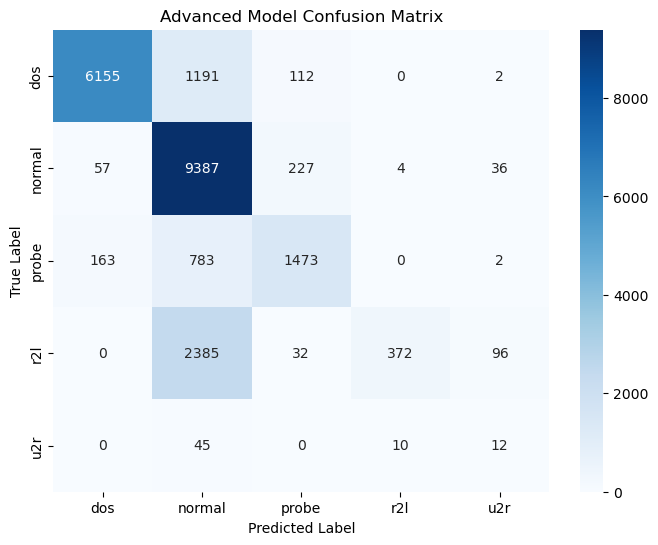

Saved as 'advanced_security_attacks_model.keras'


In [8]:
# 7. Plotting Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Advanced Model Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# Save Model
model.save('advanced_security_attacks_model.keras')
print("Saved as 'advanced_security_attacks_model.keras'")